# DCDN — a synthetic check of the division primitive

This notebook does two things, and it is deliberately small enough to read in one sitting:

1. **It verifies the claim.** On a task whose target is a quotient, a DCDN block reaches a
   normalized MSE of about `2e-05` while a DCNv2-style cross network of the same shape stops
   at `6e-01` — worse than predicting the mean.
2. **It opens the box.** Because a one-layer DCDN block is a *closed-form Laurent polynomial*
   in its inputs, the trained weights can be read back as an exact symbolic expression. The
   last section prints that expression and renders it.

Runtime: about one minute on a GPU, a few minutes on CPU.


## 1. Why a cross network cannot divide

A DCNv2 cross layer computes

$$x_{i+1} = x_0 \odot W x_i + x_i .$$

Every coordinate of $x_{i+1}$ is a **polynomial** in the coordinates of $x_0$. Stacking $L$
such layers raises the degree to $L+1$, but the result stays a polynomial: the span is
$\mathrm{span}\{x^\alpha : |\alpha| \le L+1,\ \alpha \ge 0\}$, with non-negative exponents only.

The function $n/d$ is not in that span on any domain containing $d \to 0$, and no finite
polynomial approximates it uniformly there. A network can fit $n/d$ on a bounded box away
from zero — that is Weierstrass — but the fit is a local surface, not the quotient, and it
degrades as soon as the operand scale moves.

### The DCDN recurrence

DCDN adds a division branch to the affine product crossing:

$$
\begin{aligned}
x^{(\ell+1)} ={}& x^{(\ell)}
+ \left(W_\ell x^{(\ell)} + b_\ell\right) \odot x^{(0)} \\
&+ \left(\widetilde{W}_\ell x^{(\ell)} + \widetilde{b}_\ell\right)
\odot \frac{1}{x^{(0)}}.
\end{aligned}
$$

![DCDN layer with residual, product and division branches, using the paper notation.](figures/dcdn_layer.svg)

[Layer diagram (PDF)](figures/dcdn_layer.pdf)

The coefficient notation below uses $W_p$ and $W_d$ for $W_\ell$ and
$\widetilde{W}_\ell$, and $b^p$ and $b^d$ for $b_\ell$ and
$\widetilde{b}_\ell$, respectively. The implementation uses
$\mathrm{inv}(x^{(0)})_k = 1/x^{(0)}_k$ for coordinates $k$ declared as
**denominators** by a fixed mask, and $0$ otherwise. Two properties follow immediately.

**The span becomes Laurent.** With one layer, coordinate $i$ of the output is

$$x_{1,i} = x_i\,(1 + b^p_i) + x_i \sum_j W_p[i,j]\,x_j
          + m_i \frac{1}{x_i}\Big(b^d_i + \sum_j W_d[i,j]\,x_j\Big),$$

so the exponent $-1$ is reachable. A quotient $x_j/x_i$ is a **single weight**, not an
approximation: setting $W_d[i,j] = 1$ and everything else to zero computes it exactly.

**The mask is a semantic declaration, not a convenience.** Only coordinates a contract
marks as legitimate positive denominators are inverted. The reciprocal is floored at
`div_eps` and gated by a per-row validity tensor, so a zero or missing denominator produces
a declared fallback rather than an infinity.


## 2. Setup


In [1]:
import math, sys
import torch
import torch.nn as nn

sys.path.insert(0, 'src')
from dcdn.core import DCDNCore

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)
print(f'torch {torch.__version__} on {DEV}')


torch 2.8.0+cu128 on cuda


## 3. The task

Six operands, drawn **log-uniformly over four decades** so the model sees the quotient at
many scales rather than on one narrow box. The target is $y = x_0 / x_1$; the remaining four
operands are pure distractors. Exactly one coordinate — $x_1$ — is declared a denominator.


In [2]:
F, DEN = 6, 1
MASK = [i == DEN for i in range(F)]

def sample(n, lo=0.1, hi=100.0, seed=0):
    g = torch.Generator().manual_seed(seed)
    span = math.log(hi) - math.log(lo)
    x = torch.exp(torch.rand(n, F, generator=g) * span + math.log(lo))
    y = (x[:, 0] / x[:, 1]).unsqueeze(1)
    return x, y

x, y = sample(5)
print('operands\n', x.numpy().round(3))
print('target  ', y.squeeze().numpy().round(4))


operands
 [[ 3.082 20.168  0.184  0.249  0.836  7.984]
 [ 2.953 48.903  2.327  7.887  1.113  1.604]
 [ 0.117  0.321  0.761  3.594 12.388 25.121]
 [ 0.304  0.703 11.087 55.665  1.553 41.924]
 [ 1.812  4.557 72.146  0.128  0.359  1.319]]
target   [0.1528 0.0604 0.3634 0.4328 0.3977]


## 4. Two models of the same shape

Both take the six operands, apply one interaction stack, and read out with a single linear
head. The only difference is whether the stack owns a reciprocal branch.


In [3]:
class DCDNRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.core = DCDNCore(F, num_layers=1, denominator_mask=MASK, div_eps=1e-3,
                             product_init_scale=0.1, div_init_scale=0.1,
                             runtime_value_checks=False)
        self.head = nn.Linear(F, 1)
    def forward(self, x):
        return self.head(self.core(x))

class CrossRegressor(nn.Module):
    """DCNv2-style cross: x_{i+1} = x_0 * W(x_i) + x_i. Products only."""
    def __init__(self, layers=2):
        super().__init__()
        self.w = nn.ModuleList(nn.Linear(F, F) for _ in range(layers))
        self.head = nn.Linear(F, 1)
    def forward(self, x):
        h = x
        for layer in self.w:
            h = x * layer(h) + h
        return self.head(h)


## 5. Train

The loss is MSE divided by the variance of the target, so **1.0 is exactly the constant
predictor**. This is the same normalization the offline studies use, which makes the number
below directly comparable to those tables.


In [4]:
def train(model, steps=2000, lr=3e-3, seed=1):
    model = model.to(DEV)
    xtr, ytr = sample(20000, seed=seed)
    xva, yva = sample(5000, seed=seed + 100)
    xtr, ytr, xva, yva = (t.to(DEV) for t in (xtr, ytr, xva, yva))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-6)
    var = ytr.var()
    g = torch.Generator().manual_seed(seed)
    for _ in range(steps):
        idx = torch.randint(0, len(xtr), (1024,), generator=g).to(DEV)
        opt.zero_grad()
        loss = ((model(xtr[idx]) - ytr[idx]) ** 2).mean() / var
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    with torch.no_grad():
        return float(((model(xva) - yva) ** 2).mean() / yva.var())

dcdn = DCDNRegressor(); n_dcdn = train(dcdn); dcdn = dcdn.cpu()
cross = CrossRegressor(); n_cross = train(cross); cross = cross.cpu()

print(f'DCDN   normalized MSE = {n_dcdn:.3e}')
print(f'Cross  normalized MSE = {n_cross:.3e}   (1.0 = constant predictor)')
print(f'ratio  = {n_cross / n_dcdn:,.0f}x')


DCDN   normalized MSE = 1.895e-05
Cross  normalized MSE = 6.002e-01   (1.0 = constant predictor)
ratio  = 31,675x


Expected output — DCDN around `2e-05`, the cross network around `6e-01`, a gap of roughly
**four orders of magnitude**. The cross network is not merely worse: at `0.6` it explains
40% of the variance, which on this task is what a smooth surface fitted to a quotient buys.


## 6. Explainability — reading the closed form off the weights

This is the part a black-box model cannot offer. A one-layer DCDN block followed by a linear
head is *exactly*

$$\hat{y} = c + \sum_i h_i x_i (1 + b^p_i)
          + \sum_{i,j} h_i W_p[i,j]\, x_i x_j
          + \sum_{i \in \mathcal{D}} h_i b^d_i \frac{1}{x_i}
          + \sum_{i \in \mathcal{D}, j} h_i W_d[i,j]\, \frac{x_j}{x_i},$$

with $\mathcal{D}$ the declared denominator set. Every coefficient is a product of two learned
numbers, so the trained network can be printed as a symbolic rational function with no
attribution method, no gradients, and no approximation.


In [5]:
def laurent_terms(model):
    """Exact monomial coefficients of a one-layer DCDN core plus linear head."""
    block = model.core.layers[0]
    Wp = block.product_block.weight.detach();  bp = block.product_block.bias.detach()
    Wd = block.division_block.weight.detach(); bd = block.division_block.bias.detach()
    h  = model.head.weight.detach()[0];        c  = float(model.head.bias.detach()[0])
    terms = []
    for i in range(F):
        terms.append((f'x{i}', float(h[i] * (1 + bp[i])), 'linear'))
        for j in range(F):
            terms.append((f'x{i}*x{j}', float(h[i] * Wp[i, j]), 'product'))
        if MASK[i]:
            terms.append((f'1/x{i}', float(h[i] * bd[i]), 'reciprocal'))
            for j in range(F):
                terms.append((f'x{j}/x{i}', float(h[i] * Wd[i, j]), 'ratio'))
    terms.sort(key=lambda t: -abs(t[1]))
    return terms, c

terms, constant = laurent_terms(dcdn)
print(f'constant = {constant:+.4f}')
for name, coef, kind in terms[:8]:
    print(f'  {coef:+.4f}  {name:<10} [{kind}]')


constant = -0.1526
  +1.0003  x0/x1      [ratio]
  +0.0969  x1/x1      [ratio]
  +0.0517  1/x1       [reciprocal]
  -0.0250  x0         [linear]
  +0.0137  x2         [linear]
  -0.0103  x4         [linear]
  +0.0084  x3         [linear]
  +0.0066  x1         [linear]


The leading term is `x0/x1` with a coefficient of about **+1.000**. The network did not
approximate the quotient — it *selected* it, and every remaining term is an order of
magnitude smaller.

### A readable rendering

Coefficients are grouped by monomial family and drawn on a signed axis, so the dominance of
the ratio term is visible rather than inferred from a column of numbers.


In [6]:
import sys
sys.path.insert(0, 'figures')
import style as S
from IPython.display import HTML, Math, display

VALUE_FONT = 13          # px, the coefficient label
VALUE_PAD = 10           # gap between a bar end and its label
CHAR_W = 0.62            # width of one bold digit at 1px font size

def _value_width(text):
    return len(text) * VALUE_FONT * CHAR_W

def render_terms(terms, constant, top=8, width=880, title='Learned Laurent expansion'):
    """Ratio monomials as squares, product monomials as circles — same key as
    the reach lattice below, so the two figures read together.

    The half-width available to a bar is the half-plot minus the room its own
    value label needs. Without that subtraction the longest bar pushes its
    label past the legend rule and the two overlap, which is what the first
    version of this figure did.
    """
    rows = terms[:top]
    scale = max(abs(c) for _, c, _ in rows) or 1.0
    rh, label_w, legend_w = 34, 210, 300
    bar_w = width - label_w - legend_w - 26
    height = 118 + rh * len(rows)
    zero = label_w + bar_w / 2
    reserve = max(_value_width(f'{c:+.4f}') for _, c, _ in rows) + VALUE_PAD + 6
    span = max(bar_w / 2 - reserve, 12)
    rule_x = label_w + bar_w + 26
    is_ratio = lambda k: k in ('ratio', 'reciprocal')
    out = S.head(width, height, title,
                 f'exact coefficient of each monomial in the closed form '
                 f'(constant {constant:+.4f})')
    out.append(f'<line x1="{zero}" y1="66" x2="{zero}" y2="{height-16}" stroke="{S.RULE}"/>')
    for k, (name, coef, kind) in enumerate(rows):
        y = 80 + k * rh
        w = abs(coef) / scale * span
        x = zero if coef >= 0 else zero - w
        colour = S.RATIO if is_ratio(kind) else S.PRODUCT
        out.append(f'<text x="{label_w-40}" y="{y+15}" font-size="14" fill="{S.INK}" '
                   f'text-anchor="end" font-family="{S.MONO}">{name}</text>')
        if is_ratio(kind):
            out.append(f'<rect x="{label_w-26}" y="{y+2}" width="16" height="16" rx="3" fill="{colour}"/>')
        else:
            out.append(f'<circle cx="{label_w-18}" cy="{y+10}" r="8" fill="{colour}"/>')
        out.append(f'<rect x="{x:.1f}" y="{y+2}" width="{max(w,2):.1f}" height="17" '
                   f'rx="3" fill="{colour}"/>')
        lx, anchor = ((x + w + VALUE_PAD), 'start') if coef >= 0 else ((x - VALUE_PAD), 'end')
        out.append(f'<text x="{lx:.1f}" y="{y+16}" font-size="{VALUE_FONT}" font-weight="700" '
                   f'fill="{S.INK}" text-anchor="{anchor}">{coef:+.4f}</text>')
        # the label must stay inside the plot area on both sides
        right = lx + _value_width(f'{coef:+.4f}') if coef >= 0 else lx
        left = lx - _value_width(f'{coef:+.4f}') if coef < 0 else lx
        assert right <= rule_x, f'value label crosses the legend rule: {name}'
        assert left >= label_w - 6, f'value label crosses the monomial labels: {name}'
    out += S.legend(rule_x + 30, 96, [
        ('circle', S.PRODUCT, 'Product monomial', 'DCNv2 reaches these too'),
        ('square', S.RATIO, 'Ratio monomial', 'requires the reciprocal branch'),
    ], rule_x=rule_x, height=height - 130)
    out.append('</svg>')
    return '\n'.join(out)

display(HTML(render_terms(terms, constant)))


## 7. What DCNv2 computes on the same task

The cross network is just as readable, and reading it is the point. Two cross layers
followed by a linear head expand to

$$h_1 = x \odot (W_1 x + b_1) + x, \qquad h_2 = x \odot (W_2 h_1 + b_2) + h_1,$$

so every coordinate of $h_2$ is a polynomial of degree at most three, and the readout is

$$\hat{y} = c + \sum_i w_i\Big[
  x_i(1 + b^1_i + b^2_i)
  + \sum_j \big(W_1[i,j] + W_2[i,j](1 + b^1_j)\big) x_i x_j
  + \sum_{j,k} W_2[i,j] W_1[j,k]\, x_i x_j x_k \Big].$$

Every exponent is a non-negative integer. There is no arrangement of the weights that
produces $x_0/x_1$.


In [7]:
from collections import Counter

def cross_terms(model):
    """Exact monomial coefficients of a two-layer cross plus linear head."""
    W1, b1 = model.w[0].weight.detach(), model.w[0].bias.detach()
    W2, b2 = model.w[1].weight.detach(), model.w[1].bias.detach()
    w, c = model.head.weight.detach()[0], float(model.head.bias.detach()[0])
    acc = {}
    def add(key, value):
        key = tuple(sorted(key))
        acc[key] = acc.get(key, 0.0) + float(value)
    for i in range(F):
        add((i,), w[i] * (1 + b1[i] + b2[i]))
        for j in range(F):
            add((i, j), w[i] * W1[i, j])
            add((i, j), w[i] * W2[i, j] * (1 + b1[j]))
            for k in range(F):
                add((i, j, k), w[i] * W2[i, j] * W1[j, k])
    return acc, c

def monomial_name(key):
    counts = Counter(key)
    return '*'.join(f'x{i}^{n}' if n > 1 else f'x{i}' for i, n in sorted(counts.items()))

cross_acc, cross_const = cross_terms(cross)

# The expansion is a claim about the model, so verify it against the model.
def rebuild(x):
    out = torch.full((len(x),), cross_const)
    for key, coef in cross_acc.items():
        term = torch.ones(len(x))
        for i in key:
            term = term * x[:, i]
        out = out + coef * term
    return out.unsqueeze(1)

xv, _ = sample(512, seed=999)
with torch.no_grad():
    gap = (cross(xv) - rebuild(xv)).abs().max() / cross(xv).abs().max()
print(f'expansion vs model, max relative error = {gap:.2e}')
print(f'distinct monomials = {len(cross_acc)}, degree <= 3')
print(f'monomials with a negative exponent = '
      f'{sum(1 for k in cross_acc if any(i < 0 for i in k))}')

cross_top = sorted(cross_acc.items(), key=lambda kv: -abs(kv[1]))[:8]
print(f'\nconstant = {cross_const:+.4f}')
for key, coef in cross_top:
    print(f'  {coef:+.4f}  {monomial_name(key)}')


expansion vs model, max relative error = 7.41e-07
distinct monomials = 83, degree <= 3
monomials with a negative exponent = 0

constant = +4.7027
  +0.4991  x0
  -0.1107  x0*x1
  +0.0576  x4
  +0.0387  x1
  +0.0282  x2
  +0.0243  x0*x2
  +0.0231  x0^2
  +0.0219  x0*x5


The largest term is **linear in $x_0$ alone**, next to a constant of about $+4.7$. Having no
way to write the quotient, the cross network spends its capacity on a smooth surface that
agrees with $x_0/x_1$ where the training mass is. That is why its normalized MSE is `0.60`:
it explains some variance and has not found the function.


In [8]:
cross_shaped = [(monomial_name(k), v, 'product') for k, v in cross_top]
display(HTML(render_terms(cross_shaped, cross_const,
                          title='DCNv2 &#183; learned polynomial')))


## 8. The two forms side by side

A monomial is an exponent vector $\alpha$. Both architectures reach a set of them; the sets
differ in exactly one respect.

| | DCNv2 | DCDN |
|---|---|---|
| form | polynomial | **Laurent polynomial** |
| exponents | $\alpha \ge 0$ | $\alpha \in \mathbb{Z}$, negative only on declared denominators |
| $\ell_1$-order bound after $K$ layers | $\|\alpha\|_1 \le K+1$ | $\|\alpha\|_1 \le K+1$ |
| $x_0/x_1$ | **not in the span** | one weight, $W_d[1,0]$ |
| what it learned here | 83 monomials, largest is $+0.4991\,x_0$ | 1 monomial, $+1.0003\,x_0/x_1$ |
| normalized MSE | 0.600 | 0.0000190 |

For a $K$-layer DCDN, signed degree lies between $-K$ and $K+1$; this is distinct
from the $\ell_1$-order bound above.

The lattice below draws the reachable sets for two operands. A point is **blue** when every
exponent is non-negative — those DCNv2 reaches too — and **pink** when at least one is
negative. Grey points lie inside the degree bound but are still out of reach, because one
layer can apply the reciprocal only once.


In [9]:
def reach(layers, denominators=(0, 1), dims=2):
    """Exponent vectors the recurrence can realise after `layers` steps.

    x_{i+1,k} = x_{i,k} + x_{0,k} Wp(x_i)_k + inv(x_0)_k Wd(x_i)_k

    A monomial alpha in x_i yields alpha (residual), alpha + e_k (product) and,
    when k is a declared denominator, alpha - e_k. The bias inside each block
    injects the constant monomial, which is why 1/x_k is reachable alone.
    """
    zero = tuple([0] * dims)
    basis = {tuple(1 if i == j else 0 for i in range(dims)) for j in range(dims)}
    current = {zero} | basis
    for _ in range(layers):
        nxt = set(current)
        for a in current:
            for k in range(dims):
                nxt.add(tuple(a[i] + (1 if i == k else 0) for i in range(dims)))
                if k in denominators:
                    nxt.add(tuple(a[i] - (1 if i == k else 0) for i in range(dims)))
        current = nxt
    return current

for L in (1, 2):
    inside = {a for a in reach(L) if abs(a[0]) + abs(a[1]) <= L + 1}
    product = {a for a in inside if a[0] >= 0 and a[1] >= 0}
    print(f'L={L}: {len(inside)} reachable inside the ball — '
          f'{len(product)} product, {len(inside) - len(product)} ratio')


L=1: 10 reachable inside the ball — 6 product, 4 ratio
L=2: 21 reachable inside the ball — 10 product, 11 ratio


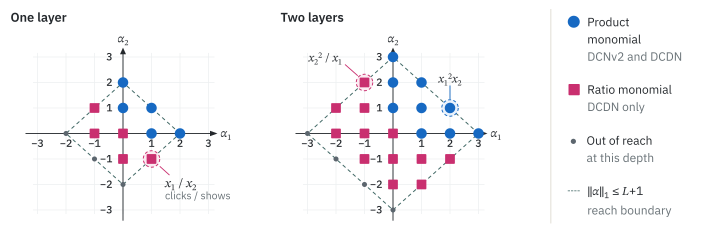

In [10]:
from IPython.display import SVG, display

# the published figure; the enumeration above is what it draws
display(SVG(filename='figures/monomial_reach.svg'))

In [11]:
def as_latex(terms, constant, top=4, cutoff=1e-3):
    kept = [(n, c) for n, c, _ in terms[:top] if abs(c) >= cutoff]
    parts = [f'{c:+.4f}' + r'\,' + n.replace('*', r' \cdot ') for n, c in kept]
    return r'\hat{y} = ' + f'{constant:+.4f}' + ''.join(parts) + r' + \varepsilon'

print('DCDN:');  display(Math(as_latex(terms, constant)))
print('DCNv2:'); display(Math(as_latex(cross_shaped, cross_const)))


DCDN:


<IPython.core.display.Math object>

DCNv2:


<IPython.core.display.Math object>